# Power and estimation at realistic signal strengths

`window_jump_dgp.ipynb` builds overnight jumps that carry on a share $\kappa$ of the previous
session's late-window slope. It studies them at $\kappa = 0.5$ and $1$, where yesterday's curve
predicts 27% and 60% of the jump. The real-data notebooks find no such term in each market's
own curves, so if it exists it is small. This notebook runs the same DGP at $R^2$ of 0, 1%, 2%
and 5%, and asks two questions. How many days does the test of $\beta = 0$ need? And what do the
estimators of `window_jump_dgp.ipynb` §6 recover at those strengths? The code is
`jump.window_power`, and the runs are cached in `artifacts/cache/` by
`scripts/make_window_power_cache.py`.

**Results.**

- Four of the five tests of $\beta = 0$ are exact and hold their 5% size. The F test at a
  BIC-chosen $M$ does not: it rejects 9.5% of the time at 62 days. Calibrating the same procedure
  by permutation restores the size (§2).
- At $R^2 = 0.02$ the oracle, told the window, reaches 80% power at about 390 days, as the
  analytic guide says. Eight principal components need about 765 days, not 740, because they
  carry 98% of the signal, not all of it. Choosing $M$ from the data costs far more. The 95%
  rule reaches 76% at a thousand days, and BIC 24%, because BIC keeps the first component, which
  carries under 1% of the signal (§3).
- On one quarter at $R^2 \le 0.05$, no estimator does better than $\hat\beta \equiv 0$, and none
  forecasts the jump better than the expanding mean (§4).
- At a thousand days the ordering of `window_jump_dgp.ipynb` holds from $R^2 = 0.02$ on.
  Method A is the most accurate and the only method that locates the window: $\hat u$ is within
  0.02 of 0.8 in 48% of datasets at $R^2 = 0.02$ and 71% at 0.05. Method B fails at every
  strength. The group lasso forecasts nearly as well as method A, without locating anything.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from fts_research.core import style
from fts_research.jump import window_dgp as wd
from fts_research.jump import window_power as wp

style.use(plt)
cfg = wp.CONFIG
grid = np.linspace(0.0, 1.0, cfg["n_bars"] + 1)
power = wp.cached_power()                      # artifacts/cache/, built by the script
rates = wp.rejection_rates(power)

## 1. Design

The data are those of `window_jump_dgp.ipynb`: one-minute GBM sessions with $\sigma = 1\%$ and
$T = 0.25$, and a jump that carries on a share $\kappa$ of the previous session's least-squares
slope over $[0.8, 1]$,
$J_t = 100mT + \kappa T(\hat b_{t-1} - 100m) + \sigma_\varepsilon\sqrt T\,Z_t$. The share of the
jump the previous curve predicts is

$$
R^2 = \frac{\kappa^2 T v}{1 + \kappa^2 T v}, \qquad v = \operatorname{Var}(\hat b)/\sigma_\varepsilon^2,
$$

which does not involve $\sigma$, so each cell is set by $R^2$ and `wd.kappa_for_r2` inverts it.

| | value | |
|---|---|---|
| $R^2$ | 0, 0.01, 0.02, 0.05 | realistic cells, $\kappa$ from `kappa_for_r2` |
| $\kappa$ | 0.25, 0.5, 1 | reference cells, those of `window_jump_dgp.ipynb` |
| $n$, pairs $(J_t, X_{t-1})$ | 62, 125, 250, 390, 500, 765, 1000 | 62 is the notebook's quarter |
| replications | 1,000 at $R^2 = 0$, 500 elsewhere | size needs the extra precision |
| permutations | 999 | behind the BIC test |

Each replication is drawn once, at $\kappa = 0$, and moved to every other $\kappa$ exactly by
adding $\kappa T(\hat b_{t-1} - 100m)$, since $\kappa$ changes no draw. The cells of a
replication therefore share their curves and noise, and differ only in the signal.

In [2]:
v = wd.window_slope_sd(grid, cfg["start"], 1.0) ** 2
print(f"v = {v:.3f} on the one-minute grid")
wp.design_cells().set_index("cell").round(4)

v = 5.926 on the one-minute grid


,kind,kappa,r2
cell,,,
R2=0,r2,0.0000,0.0000
R2=0.01,r2,0.0826,0.0100
R2=0.02,r2,0.1174,0.0200
R2=0.05,r2,0.1885,0.0500
kappa=0.25,kappa,0.2500,0.0847
kappa=0.5,kappa,0.5000,0.2703
kappa=1,kappa,1.0000,0.5970


## 2. Five tests of $\beta = 0$

Each regresses $J_t$ on yesterday's curve, with an intercept, on $n$ pairs.

| test | regressors | $M$ chosen | exact? |
|---|---|---|---|
| **slope** | $\hat b_{t-1}$ | -- (the oracle: told the window and the shape of $\beta$) | yes |
| **M8** | first 8 principal component scores | fixed, from knowing $\beta$ (`window_jump_dgp.ipynb` §5) | yes |
| **var95** | first $M$ scores | smallest $M$ holding 95% of the curves' variance | yes |
| **BIC, naive** | first $M$ scores | $M \in \{1, \dots, 10\}$ minimising BIC; F table | no |
| **BIC, permutation** | first $M$ scores | the same; permutation distribution | yes |

Under the null the jumps are i.i.d. and independent of the curves, so given the curves the first
three are exact F tests. The naive BIC test is not: $M$ is chosen by looking at the jumps, and then
tested at the $M$ that fitted them best. Permuting the jumps against the curves and rerunning
*select-then-test* on each permutation gives that procedure's exact null distribution, and
$p = (1 + \#\{p^*_b \le p\})/(B + 1)$ is exact
[[67]](../docs/references.md#ref-phipson-smyth-2010).

**The analytic guide.** With an intercept and Gaussian regressors the F statistic is noncentral F
given the regressors, with noncentrality $f^2\chi^2_{n-1}$, where $f^2 = R^2/(1 - R^2)$. Its power
is therefore a one-dimensional integral, exact for the oracle. For the first $M$ population
components of a Brownian curve, the signal outside them is independent noise, so
$f^2 = sR^2/(1 - sR^2)$, with $s$ the share of the signal they carry (0.98 for $M = 8$). The
M8 test uses sample components, so for it this is a guide.

**Size.** The table gives each test's rejection rate at $R^2 = 0$, in per cent, over 1,000
replications; its Monte Carlo standard error is 0.69 points.

In [3]:
null = rates[rates["cell"] == "R2=0"]
size = null.pivot(index="test", columns="n", values="rate").loc[list(wp.TESTS)] * 100
se = wp.mc_se(0.05, cfg["n_rep_size"]) * 100
print(f"5% +- 2 SE: [{5 - 2 * se:.2f}, {5 + 2 * se:.2f}]")
exact = null[null["test"].isin(wp.EXACT_TESTS)]
outside = int((np.abs(exact["rate"] - 0.05) > 2 * wp.mc_se(0.05, exact["n_rep"])).sum())
p_out = stats.binom.sf(outside - 1, len(exact), 2 * stats.norm.sf(2))
print(f"exact-test cells outside 2 SE: {outside} of {len(exact)} "
      f"(expected {len(exact) * 2 * stats.norm.sf(2):.1f}; P(at least {outside}) = {p_out:.2f})")
pooled = (null.groupby("test")[["rate", "n_rep"]]
          .apply(lambda d: 100 * np.average(d["rate"], weights=d["n_rep"])))
print("pooled over n, %: " + ", ".join(f"{t} {pooled[t]:.2f}" for t in wp.TESTS)
      + f"  (SE {wp.mc_se(0.05, 7 * cfg['n_rep_size']) * 100:.2f})")
size.round(1)

5% +- 2 SE: [3.62, 6.38]
exact-test cells outside 2 SE: 3 of 28 (expected 1.3; P(at least 3) = 0.13)
pooled over n, %: slope 5.29, M8 4.80, var95 5.11, bic_naive 7.14, bic_perm 5.14  (SE 0.26)


n,62,125,250,390,500,765,1000
test,,,,,,,
slope,4.3,5.7,6.4,5.7,5.8,4.9,4.2
M8,4.8,6.7,4.4,5.4,5.0,3.9,3.4
var95,4.1,6.0,5.2,5.1,5.9,5.5,4.0
bic_naive,9.5,7.9,7.8,6.2,6.0,6.7,5.9
bic_perm,4.7,5.2,5.4,4.8,4.9,5.7,5.3


The four exact tests hold their size. Three of their 28 cells fall outside the two-standard-error
band, which is what exactness predicts (about 1.3 by chance), and each test's size pooled over $n$
is within 0.3 points of 5%. A per-cell band of $\pm 1.4$ points is the right tolerance for one
cell, not for 28 at once. The naive BIC test rejects 9.5% of the time at $n = 62$ and 7.1%
pooled. The permutation repairs it, and every comparison of power below is between tests of the
right size.

## 3. Power

The figure plots each exact test's rejection rate against $n$, one line per $R^2$, with
two-standard-error bars. Dashed lines are the analytic guide, where one exists. The dotted lines
mark 5% and 80%. A test that could see the signal would rise to 1, and one that could not would
stay at 5%.

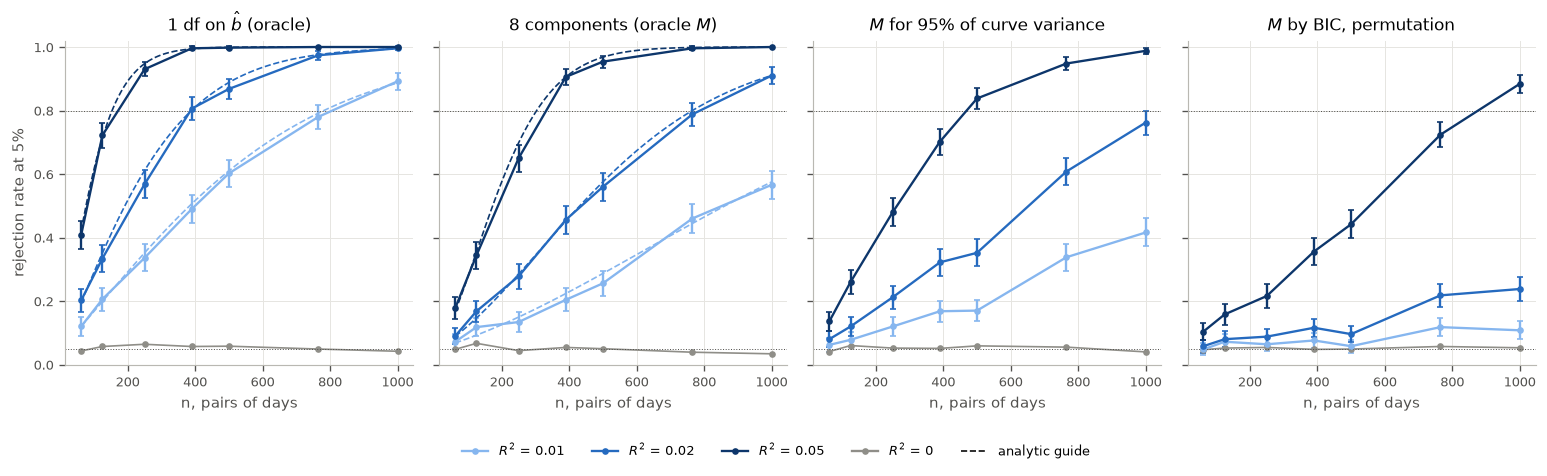

In [4]:
PANELS = (("slope", r"1 df on $\hat b$ (oracle)"), ("M8", r"8 components (oracle $M$)"),
          ("var95", r"$M$ for 95% of curve variance"), ("bic_perm", r"$M$ by BIC, permutation"))
R2S = (0.01, 0.02, 0.05)
colour = dict(zip(R2S, style.ordinal(3)))
share8 = wp.signal_share(cfg["m_oracle"])
n_fine = np.linspace(min(cfg["n_power"]), max(cfg["n_power"]), 120)
guide = {"slope": lambda n, r2: wp.f_test_power(n, 1, wp.effective_f2(r2)),
         "M8": lambda n, r2: wp.f_test_power(n, 8, wp.effective_f2(r2, share8))}

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, (test, title) in zip(axes, PANELS):
    for r2 in R2S:
        d = rates[(rates["test"] == test) & (rates["cell"] == f"R2={r2:g}")]
        ax.errorbar(d["n"], d["rate"], yerr=2 * d["se"], color=colour[r2], marker="o", ms=3,
                    lw=1.4, capsize=2)
        if test in guide:
            ax.plot(n_fine, [guide[test](n, r2) for n in n_fine], color=colour[r2], lw=1,
                    ls="--")
    d = rates[(rates["test"] == test) & (rates["cell"] == "R2=0")]
    ax.plot(d["n"], d["rate"], color=style.CONTROL, marker="o", ms=3, lw=1)
    for level in (0.05, 0.8):
        ax.axhline(level, color=style.MUTED, lw=0.6, ls=":")
    ax.set_title(title)
    ax.set_xlabel("n, pairs of days")
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("rejection rate at 5%")
fig.legend(handles=[plt.Line2D([], [], color=colour[r2], marker="o", ms=3,
                               label=fr"$R^2$ = {r2:g}") for r2 in R2S]
           + [plt.Line2D([], [], color=style.CONTROL, marker="o", ms=3, label=r"$R^2$ = 0"),
              plt.Line2D([], [], color=style.INK, lw=1, ls="--", label="analytic guide")],
           loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
style.save_figure(fig, "window_power")
plt.show()

In [5]:
realistic = rates[rates["cell"].isin([f"R2={r2:g}" for r2 in R2S])]
(realistic.pivot_table(index=["cell", "test"], columns="n", values="rate", sort=False)
 .loc[[(f"R2={r2:g}", t) for r2 in R2S for t in wp.TESTS]] * 100).round(1)

n                  62    125   250   390   500    765    1000
cell    test                                                 
R2=0.01 slope      12.0  20.6  33.6  49.0  60.2   78.0   89.2
        M8          7.2  11.8  13.4  20.4  25.6   46.0   56.6
        var95       6.2   7.8  12.0  16.8  17.0   33.8   41.6
        bic_naive   9.4  10.2   7.2   8.6   7.6   13.0   12.8
        bic_perm    4.8   7.2   6.4   7.6   5.8   11.8   10.8
R2=0.02 slope      20.2  33.4  56.8  80.6  86.8   97.4   99.6
        M8          9.0  16.8  27.8  45.6  56.0   78.8   91.0
        var95       8.0  12.0  21.2  32.2  35.2   60.8   76.2
        bic_naive  11.4  11.6  10.4  12.8  10.6   23.0   25.6
        bic_perm    5.8   8.0   8.8  11.6   9.6   21.8   23.8
R2=0.05 slope      40.8  72.2  93.0  99.6  99.8  100.0  100.0
        M8         17.8  34.4  65.0  90.6  95.4   99.6  100.0
        var95      13.6  26.0  48.0  70.2  83.8   94.8   98.8
        bic_naive  15.4  19.0  23.4  37.8  45.8   72.8   88.8
        bic_perm   10.4  15.8  21.6  35.6  44.2   72.4   88.4

The table gives the rejection rates behind the figure, in per cent, with the naive BIC test
included for reference.

**The item's check.** At $R^2 = 0.02$ the guide puts 80% power at about 390 days for the oracle
and, because eight components hold 98% of the signal rather than all of it, at about 765 for
the M8 test. The cell below sets both against the simulation, and reads off where each simulated
curve crosses 80% by interpolating between the grid points of $n$.

In [6]:
at = rates.set_index(["cell", "test", "n"])
f2 = {"slope": wp.effective_f2(0.02), "M8": wp.effective_f2(0.02, share8)}
df1 = {"slope": 1, "M8": cfg["m_oracle"]}
rows = []
for test, n in (("slope", 390), ("M8", 765)):
    r = at.loc[("R2=0.02", test, n)]
    curve = at.loc["R2=0.02"].loc[test]["rate"]
    k = int(np.argmax(curve.to_numpy() >= 0.8))
    n80 = np.interp(0.8, curve.to_numpy()[k - 1:k + 1], curve.index.to_numpy()[k - 1:k + 1])
    rows.append({"test": test, "n": n, "simulated": r["rate"], "MC SE": r["se"],
                 "analytic": wp.f_test_power(n, df1[test], f2[test]),
                 "n for 80%, analytic": wp.n_for_power(df1[test], f2[test]),
                 "n for 80%, simulated": n80})
pd.DataFrame(rows).set_index("test").round(3)

,n,simulated,MC SE,analytic,"n for 80%, analytic","n for 80%, simulated"
test,,,,,,
slope,390,0.806,0.018,0.801,389.187,386.471
M8,765,0.788,0.018,0.800,765.200,788.115


The oracle's simulated power, 0.806 at $n = 390$, is the analytic 0.801 to within a third of a
standard error, and across all 28 cells of $R^2 \le 0.05$ and $n$ it never leaves the analytic
curve by much more than two Monte Carlo standard errors (`tests/test_window_power.py`). The M8 test reaches 0.788 at
$n = 765$ against the guide's 0.800: estimating the components costs it about 20 days. The item's
"about 740 days" for the M8 test assumed all of the signal; eight components carry 98% of it,
which moves the guide to 765.

The figure's main message is the gap between the panels. At $R^2 = 0.02$, which is about what the
real-data notebooks could still be missing, the oracle needs about 390 days, and the realistic
choices need far more. The 95% rule keeps four or five components, which carry 43% and 65% of
the signal, and does not reach 80% even at a thousand days. BIC does worst of all, because it is
asked the wrong question, as the next cell shows.

In [7]:
choice = power[power["n"].isin([62, 1000])].groupby(["cell", "n"])["M_bic"]
picked = pd.DataFrame({"BIC picks M = 1": choice.apply(lambda m: (m == 1).mean()),
                       "median M, 95% rule": power[power["n"].isin([62, 1000])]
                       .groupby(["cell", "n"])["M_var95"].median()})
print(f"share of the signal in the first component: {wp.signal_share(1):.4f}; "
      f"in the first four: {wp.signal_share(4):.3f}; in the first five: {wp.signal_share(5):.3f}")
picked.loc[[c for c in wp.design_cells()["cell"]]].round(3)

share of the signal in the first component: 0.0082; in the first four: 0.431; in the first five: 0.647


BIC picks M = 1  median M, 95% rule
cell       n                                        
R2=0       62              0.920                 4.0
           1000            0.989                 5.0
R2=0.01    62              0.918                 4.0
           1000            0.930                 5.0
R2=0.02    62              0.904                 4.0
           1000            0.802                 5.0
R2=0.05    62              0.862                 4.0
           1000            0.122                 5.0
kappa=0.25 62              0.800                 4.0
           1000            0.000                 5.0
kappa=0.5  62              0.356                 4.0
           1000            0.000                 5.0
kappa=1    62              0.000                 4.0
           1000            0.000                 5.0

BIC chooses $M$ by how well the first $M$ components fit the jumps, and the first components
carry almost none of the signal: under 1% is in the first, because $\hat b$ is a slope over the
last fifth of the session, where the low-order components are nearly flat. Adding component 3
to 8 gains about $n\log(1 + f^2)$ in fit, against a penalty of $\log n$ for each component, and
at $R^2 = 0.02$ that gain does not pay for itself in four datasets of five even at a thousand
days. So BIC stops at $M = 1$, with nothing to test. The defect is in the criterion, not in the calibration:
selecting components by variance or by in-sample fit puts the signal in the discarded tail
whenever $\beta$ lives where the curves vary least. A data-driven $M$ that keeps power here
has to search the components for the signal rather than rank them by fit. The adaptive Neyman
statistic, the maximum over $M$ of the standardised F, is such a test, and the permutation
calibration above would make it exact.

## 4. The estimators

The estimators are those of §6 of `window_jump_dgp.ipynb`:

- the untruncated principal component fit, with $M = 8$ chosen knowing $\beta$;
- truncFLR methods A and B, told that the window ends at the close, with $\lambda$ from the
  paper's §3.2;
- the fdaSP group lasso, told nothing, with $\lambda$ from ten-fold cross-validation.

Two more rules run alongside on the same data: $M$ by BIC for the untruncated fit, and the
one-standard-error $\lambda$ for the group lasso. Every cell is run at $n$ = 62, 250, 500 and
1,000 pairs, with 100 replications each, on the same datasets across cells.

Each fit is scored on four counts:

- its relative ISE, $\int(\hat\beta - \beta)^2 / \int\beta^2$, on which $\hat\beta \equiv 0$
  scores 1;
- whether its implied window start $\hat u$ lies within 0.02 of 0.8;
- whether it sets $\hat\beta$ to zero anywhere, or everywhere;
- its forecasts of the next 63 jumps.

The records are kept per replication, so the paired tests of item 2 need no refit. The first
table is one quarter, $n = 62$.

In [8]:
methods = wp.cached_methods()
support = wp.cached_methods_support()
CELLS = list(wp.design_cells()["cell"])
NAME = {"FPCA-oracle": "untruncated, M = 8 (oracle)", "FPCA-BIC": "untruncated, M by BIC",
        "HH-A": "truncFLR, method A", "HH-B": "truncFLR, method B",
        "OGL-CV": "group lasso, CV", "OGL-1SE": "group lasso, one-SE"}
SHOWN = ["R2=0.01", "R2=0.02", "R2=0.05", "kappa=0.5", "kappa=1"]
R2_OF = wp.design_cells().set_index("cell")["r2"]
HEAD = {c: f"R2 = {R2_OF[c]:.2f}" for c in CELLS}


def rise_text(x):
    q = x.quantile([0.25, 0.5, 0.75])
    return f"{q[0.5]:.2f} [{q[0.25]:.2f}, {q[0.75]:.2f}]"


rise = (methods[methods["cell"].isin(SHOWN)]
        .groupby(["n", "method", "cell"], sort=False)["rise"].apply(rise_text)
        .unstack("cell")[SHOWN].rename(columns=HEAD))
print("relative ISE, median [quartiles], at n = 62 (a quarter):")
rise.loc[62].loc[list(wp.METHODS)].rename(index=NAME)

relative ISE, median [quartiles], at n = 62 (a quarter):


cell,R2 = 0.01,R2 = 0.02,R2 = 0.05,R2 = 0.27,R2 = 0.60
method,,,,,
"untruncated, M = 8 (oracle)","8.93 [5.56, 14.68]","4.56 [2.87, 7.43]","1.96 [1.26, 3.09]","0.54 [0.41, 0.74]","0.35 [0.29, 0.43]"
"untruncated, M by BIC","1.01 [1.00, 1.02]","1.00 [1.00, 1.01]","1.00 [1.00, 1.00]","0.87 [0.65, 1.00]","0.38 [0.30, 0.46]"
"truncFLR, method A","384.18 [70.97, 1793.42]","177.66 [11.59, 852.44]","19.66 [1.11, 142.38]","0.38 [0.18, 0.76]","0.16 [0.09, 0.27]"
"truncFLR, method B","315.48 [23.23, 8444.32]","66.53 [7.28, 2777.66]","17.47 [2.53, 514.74]","2.77 [1.11, 10.77]","6.24 [1.52, 15.84]"
"group lasso, CV","1.00 [1.00, 1.09]","1.00 [1.00, 1.05]","1.00 [1.00, 1.04]","0.45 [0.31, 0.69]","0.24 [0.20, 0.34]"
"group lasso, one-SE","1.00 [1.00, 1.00]","1.00 [1.00, 1.00]","1.00 [1.00, 1.00]","0.82 [0.50, 1.00]","0.33 [0.26, 0.40]"


In [9]:
print("relative ISE, median [quartiles], at n = 1000 (four years):")
rise.loc[1000].loc[list(wp.METHODS)].rename(index=NAME)

relative ISE, median [quartiles], at n = 1000 (four years):


cell,R2 = 0.01,R2 = 0.02,R2 = 0.05,R2 = 0.27,R2 = 0.60
method,,,,,
"untruncated, M = 8 (oracle)","0.68 [0.50, 1.07]","0.44 [0.35, 0.63]","0.30 [0.26, 0.36]","0.21 [0.20, 0.23]","0.20 [0.19, 0.21]"
"untruncated, M by BIC","1.00 [1.00, 1.00]","1.00 [1.00, 1.00]","0.52 [0.41, 0.73]","0.20 [0.18, 0.21]","0.16 [0.15, 0.17]"
"truncFLR, method A","0.93 [0.36, 26.54]","0.30 [0.16, 0.74]","0.16 [0.10, 0.29]","0.09 [0.06, 0.11]","0.06 [0.04, 0.07]"
"truncFLR, method B","79.74 [7.08, 1213.93]","7.71 [2.28, 98.72]","3.08 [1.20, 8.10]","1.68 [1.07, 4.06]","1.17 [0.94, 1.75]"
"group lasso, CV","0.77 [0.44, 1.00]","0.43 [0.30, 0.62]","0.28 [0.22, 0.36]","0.17 [0.15, 0.18]","0.13 [0.12, 0.14]"
"group lasso, one-SE","1.00 [1.00, 1.00]","1.00 [1.00, 1.00]","0.92 [0.70, 1.00]","0.27 [0.24, 0.31]","0.18 [0.17, 0.18]"


On one quarter at $R^2 \le 0.05$ no method estimates $\beta$: every median relative ISE is at
least 1, the error of returning zero. Eight coefficients estimated from 62 jumps add more noise
than the signal they capture, so the oracle's median is 4.56 at $R^2 = 0.02$. Method A fits its
window to the noise (177.66). The BIC fit and the group lasso score 1.00 because they mostly
return zero, which is the best available answer from so little data.

At a thousand days the ordering of `window_jump_dgp.ipynb` holds from $R^2 = 0.02$ on. Method A
is the most accurate (0.30), the group lasso (0.43) and the oracle (0.44) follow, and method B
fails at every strength. At $R^2 = 0.01$, even a thousand days leave method A's median at 0.93,
with an upper quartile of 26.54.

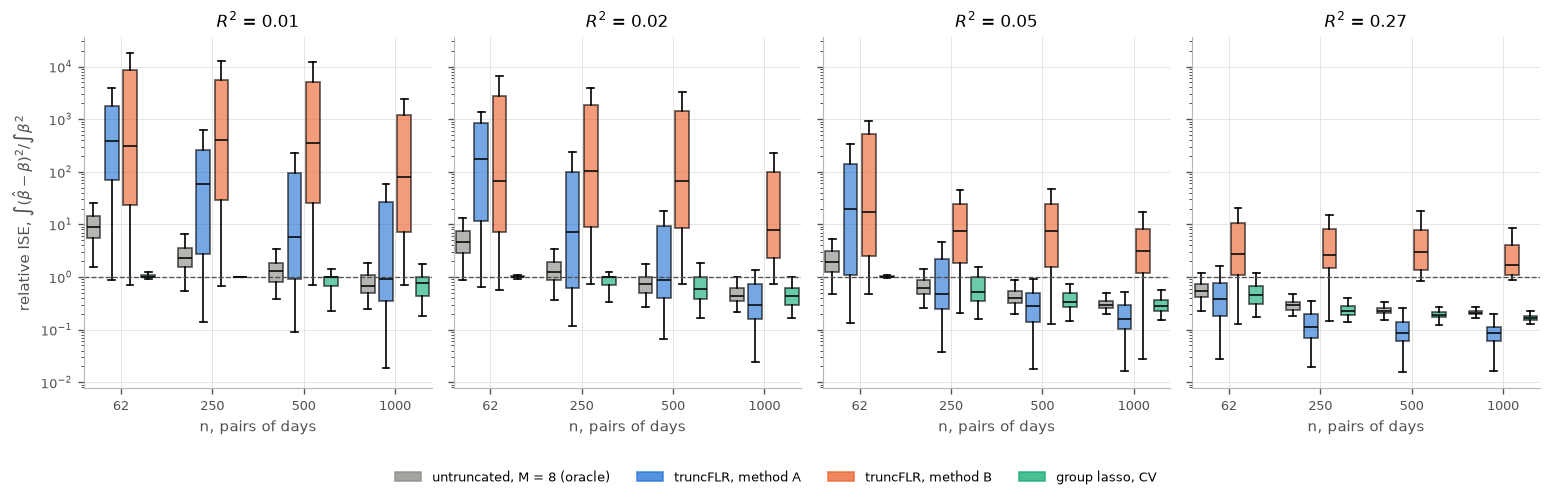

In [10]:
FOUR = ("FPCA-oracle", "HH-A", "HH-B", "OGL-CV")
COLOUR = {"FPCA-oracle": style.CONTROL, "HH-A": style.METHOD_COLOUR["HH-A"],
          "HH-B": style.METHOD_COLOUR["HH-B"], "OGL-CV": style.METHOD_COLOUR["OGL"]}
NS = sorted(cfg["n_methods"])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
for ax, cell in zip(axes, ["R2=0.01", "R2=0.02", "R2=0.05", "kappa=0.5"]):
    for i, n in enumerate(NS):
        for j, m in enumerate(FOUR):
            v = methods.query("cell == @cell and n == @n and method == @m")["rise"]
            bp = ax.boxplot(v, positions=[i * (len(FOUR) + 1) + j], widths=0.75,
                            showfliers=False, patch_artist=True)
            bp["boxes"][0].set(facecolor=COLOUR[m], alpha=0.65)
            bp["medians"][0].set(color=style.INK)
    ax.axhline(1, color=style.MUTED, lw=0.8, ls="--")
    ax.set_yscale("log")
    ax.set_xticks([i * (len(FOUR) + 1) + 1.5 for i in range(len(NS))], [str(n) for n in NS])
    ax.set_xlabel("n, pairs of days")
    ax.set_title(fr"$R^2$ = {R2_OF[cell]:.2f}")
axes[0].set_ylabel(r"relative ISE, $\int(\hat\beta - \beta)^2 / \int\beta^2$")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOUR[m], alpha=0.8, label=NAME[m])
                    for m in FOUR],
           loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
style.save_figure(fig, "window_methods_realistic")
plt.show()

Each box spans the quartiles of the relative ISE over 100 replications, on a log scale. The
whiskers reach 1.5 interquartile ranges, and outliers are not drawn. The dashed line at 1 is
the error of $\hat\beta \equiv 0$, so a method that learns $\beta$ falls below it as $n$ grows.
The group lasso sits on the line at small $n$, because it returns zero. At $R^2 = 0.02$,
method A's median crosses the line between 250 and 500 days, and the method keeps a long upper
tail. Method B's median never crosses it.

In [11]:
share = (methods.groupby(["method", "cell", "n"])[["u_hit", "zeroes_any", "zeroes_all"]]
         .mean())
window = share.loc["HH-A", "u_hit"].unstack("n").loc[CELLS].rename(index=HEAD)
print("method A: share of replications with |u_hat - 0.8| <= 0.02")
print(window.round(2).to_string())
failed = (methods[methods["method"] == "HH-A"].groupby(["cell", "n"])["lam_failed"].mean()
          .unstack("n").loc[CELLS].rename(index=HEAD))
print("\nmethod A: share of replications where section 3.2 could not rank the lambdas")
print(failed.round(2).to_string())
zeroes = pd.concat({NAME[m]: share.loc[m, "zeroes_any"].unstack("n").loc[CELLS]
                    for m in ("OGL-CV", "OGL-1SE")}).rename(index=HEAD)
print("\ngroup lasso: share of replications zeroing any of [0, 1]")
print(zeroes.round(2).to_string())
nulls = pd.concat({NAME[m]: share.loc[m, "zeroes_all"].unstack("n").loc[CELLS]
                   for m in ("OGL-CV", "OGL-1SE")}).rename(index=HEAD)
print("\ngroup lasso: share of replications returning beta_hat = 0 everywhere")
print(nulls.round(2).to_string())

method A: share of replications with |u_hat - 0.8| <= 0.02
n          62    250   500   1000
cell                             
R2 = 0.00  0.03  0.03  0.00  0.03
R2 = 0.01  0.03  0.09  0.14  0.32
R2 = 0.02  0.04  0.17  0.27  0.48
R2 = 0.05  0.10  0.40  0.52  0.71
R2 = 0.08  0.20  0.62  0.65  0.81
R2 = 0.27  0.38  0.89  0.90  0.96
R2 = 0.60  0.74  0.94  0.96  0.99

method A: share of replications where section 3.2 could not rank the lambdas
n          62    250   500   1000
cell                             
R2 = 0.00  0.26  0.37  0.39  0.34
R2 = 0.01  0.24  0.25  0.26  0.17
R2 = 0.02  0.21  0.24  0.12  0.03
R2 = 0.05  0.29  0.09  0.01  0.00
R2 = 0.08  0.32  0.03  0.00  0.00
R2 = 0.27  0.01  0.00  0.00  0.00
R2 = 0.60  0.00  0.00  0.00  0.00

group lasso: share of replications zeroing any of [0, 1]
n                              62    250   500   1000
                    cell                             
group lasso, CV     R2 = 0.00  0.81  0.90  0.86  0.82
                    R2 = 0.01  

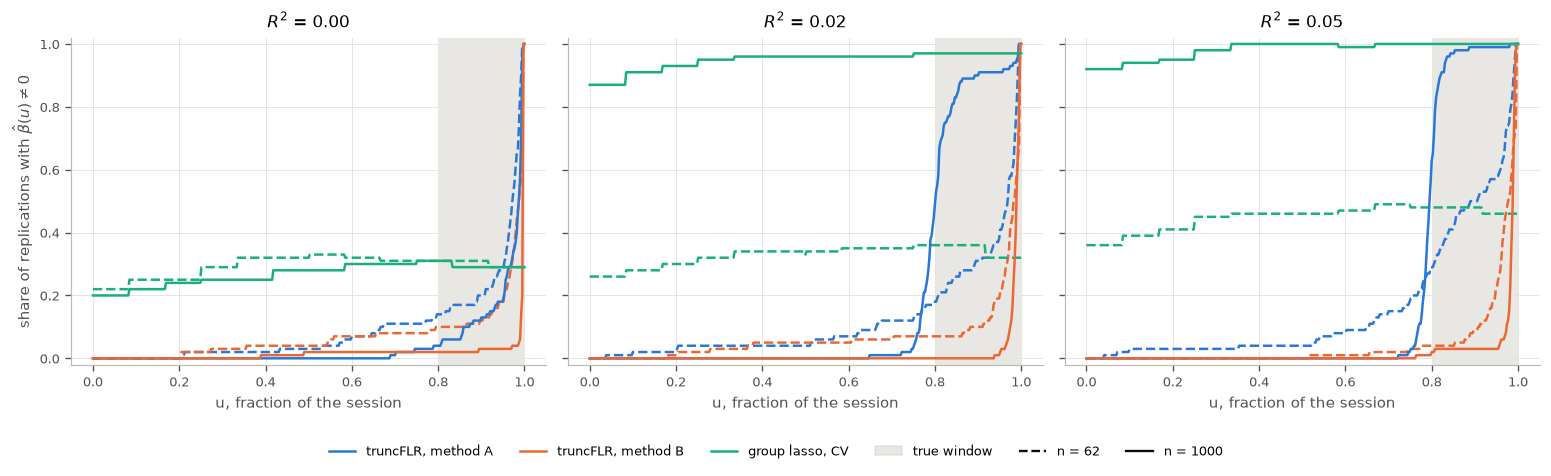

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, cell in zip(axes, ["R2=0", "R2=0.02", "R2=0.05"]):
    ax.axvspan(cfg["start"], 1, color=style.BAND, alpha=0.6, lw=0)
    for n, ls in ((62, "--"), (1000, "-")):
        for m in ("HH-A", "HH-B", "OGL-CV"):
            d = support.query("cell == @cell and n == @n and method == @m")
            ax.plot(d["s"], d["in_support"], color=COLOUR[m], lw=1.5, ls=ls)
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(fr"$R^2$ = {R2_OF[cell]:.2f}")
    ax.set_xlabel("u, fraction of the session")
axes[0].set_ylabel(r"share of replications with $\hat\beta(u) \neq 0$")
fig.legend(handles=[plt.Line2D([], [], color=COLOUR[m], lw=1.5, label=NAME[m])
                    for m in ("HH-A", "HH-B", "OGL-CV")]
           + [plt.Rectangle((0, 0), 1, 1, color=style.BAND, alpha=0.6, label="true window")]
           + [plt.Line2D([], [], color=style.INK, ls=ls, label=f"n = {n}")
              for n, ls in ((62, "--"), (1000, "-"))],
           loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
style.save_figure(fig, "window_methods_support")
plt.show()

**Method A** finds the window more often as the data grow. At $R^2 = 0.02$, $\hat u$ is within
0.02 of 0.8 in 4% of quarters and in 48% of datasets at a thousand days; at $R^2 = 0.05$ the
latter is 71%. Under the null about 3% of its windows land there by chance. Its §3.2 criterion
cannot rank the $\lambda$ grid in up to two fifths of datasets at $R^2 \le 0.02$ (0.39 under the
null at 500 days). The fit then takes the smallest $\lambda$ on the grid, as `bench.study` does.

**The group lasso** never locates the window. At realistic strength its sparsity switches the
whole function off instead:

- cross-validation returns $\hat\beta \equiv 0$ in 64% of quarters at $R^2 = 0.02$, and in 3%
  of datasets at a thousand days;
- the one-standard-error rule returns it in essentially every dataset at $R^2 \le 0.02$.

That makes it a test of $\beta = 0$, not an estimate of where $\beta$ is non-zero.

**Reading the figure.** A truncFLR fit is non-zero exactly on $[\hat u, 1]$, so its curve is
the empirical distribution function of $\hat u$. A method that always found the window would
step from 0 to 1 at 0.8 (shaded). Method A's solid curve, at a thousand days, rises steeply at
0.8 when there is a signal, and stays at the close under the null. Method B's stays at the
close throughout. For the group lasso the curve is the share of fits not zeroed at $u$, and its
flat level is the share that kept any of the function at all.

In [13]:
pooled = methods.groupby(["cell", "n", "method"], sort=False)[["mse_test", "mse_bench"]].sum()
held = (1 - pooled["mse_test"] / pooled["mse_bench"]).unstack("method")[list(wp.METHODS)]
held = held.rename(columns=NAME)
held.insert(0, "true R2", [R2_OF[c] for c, _ in held.index])
print("held-out R2 on the next 63 jumps, pooled over replications, against the expanding mean")
held.loc[[(c, n) for c in CELLS if c != "kappa=0.25" for n in NS]].round(3)

held-out R2 on the next 63 jumps, pooled over replications, against the expanding mean


method          true R2  untruncated, M = 8 (oracle)  untruncated, M by BIC  \
cell      n                                                                   
R2=0      62      0.000                       -0.129                 -0.018   
          250     0.000                       -0.027                 -0.005   
          500     0.000                       -0.015                 -0.003   
          1000    0.000                       -0.010                 -0.002   
R2=0.01   62      0.010                       -0.119                 -0.027   
          250     0.010                       -0.017                 -0.007   
          500     0.010                       -0.003                 -0.003   
          1000    0.010                        0.001                 -0.002   
R2=0.02   62      0.020                       -0.109                 -0.027   
          250     0.020                       -0.007                 -0.005   
          500     0.020                        0.008                 -0.003   
          1000    0.020                        0.011                 -0.002   
R2=0.05   62      0.050                       -0.079                 -0.029   
          250     0.050                        0.022                 -0.002   
          500     0.050                        0.038                  0.014   
          1000    0.050                        0.040                  0.031   
kappa=0.5 62      0.270                        0.152                  0.066   
          250     0.270                        0.239                  0.231   
          500     0.270                        0.252                  0.251   
          1000    0.270                        0.255                  0.257   
kappa=1   62      0.597                        0.501                  0.487   
          250     0.597                        0.562                  0.571   
          500     0.597                        0.568                  0.576   
          1000    0.597                        0.574                  0.583   

method          truncFLR, method A  truncFLR, method B  group lasso, CV  \
cell      n                                                               
R2=0      62                -0.078              -0.170           -0.037   
          250               -0.023              -0.057           -0.009   
          500               -0.012              -0.037           -0.003   
          1000              -0.006              -0.022           -0.001   
R2=0.01   62                -0.075              -0.159           -0.035   
          250               -0.017              -0.029           -0.009   
          500                0.001              -0.034            0.001   
          1000               0.003              -0.007            0.004   
R2=0.02   62                -0.068              -0.131           -0.038   
          250               -0.005              -0.022           -0.004   
          500                0.011              -0.025            0.009   
          1000               0.016              -0.001            0.013   
R2=0.05   62                -0.040              -0.095           -0.039   
          250                0.025              -0.004            0.021   
          500                0.044              -0.008            0.040   
          1000               0.047               0.007            0.042   
kappa=0.5 62                 0.187               0.023            0.146   
          250                0.256               0.035            0.247   
          500                0.264               0.039            0.256   
          1000               0.268               0.042            0.261   
kappa=1   62                 0.557               0.071            0.519   
          250                0.586               0.083            0.579   
          500                0.587               0.093            0.580   
          1000               0.593               0.098            0.58

The held-out $R^2$ is $1 - \sum e^2 / \sum e_0^2$, where $e$ is a method's forecast error on the
next 63 jumps of every replication and $e_0$ is the expanding mean's. The true $R^2$ is what a
forecaster that knew $\beta$ would approach.

- **One quarter.** At $R^2 \le 0.05$ every method forecasts worse than the null's expanding
  mean. The oracle falls short by 0.109 at $R^2 = 0.02$. Only the one-standard-error group lasso
  breaks even, by returning zero.
- **A thousand days, $R^2 = 0.02$.** Method A recovers 0.016 of the possible 0.020, the group
  lasso 0.013 and the oracle 0.011. Method B forecasts no better than the mean.

Predicting the jump and locating the window are different targets. The group lasso comes close
to method A on the first and never achieves the second.